Page 1: 20 books
Page 2: 20 books
Page 3: 20 books
Page 4: 20 books
Page 5: 20 books
                                   Title  Price  Rating Availability  \
0                   A Light in the Attic  51.77       3     In stock   
1                     Tipping the Velvet  53.74       1     In stock   
2                             Soumission  50.10       1     In stock   
3                          Sharp Objects  47.82       4     In stock   
4  Sapiens: A Brief History of Humankind  54.23       5     In stock   

                                                 URL  
0  https://books.toscrape.com/catalogue/a-light-i...  
1  https://books.toscrape.com/catalogue/tipping-t...  
2  https://books.toscrape.com/catalogue/soumissio...  
3  https://books.toscrape.com/catalogue/sharp-obj...  
4  https://books.toscrape.com/catalogue/sapiens-a...   

Title            object
Price           float64
Rating            int64
Availability     object
URL              object
dtype: object 

Saved 100 rows

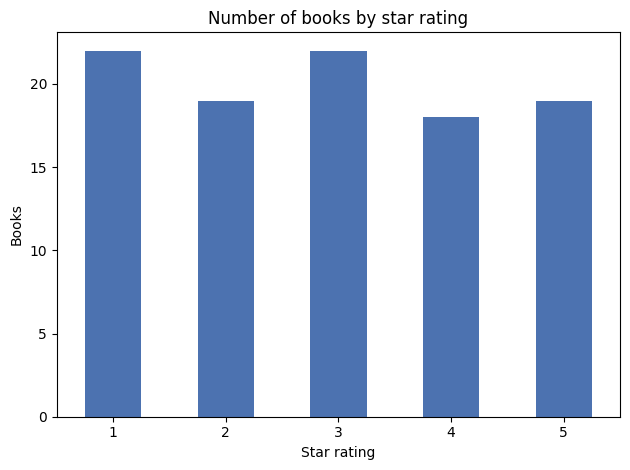

In [5]:

import argparse
import time
from urllib.parse import urljoin

import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup

BASE = "https://books.toscrape.com/catalogue/"
PAGE_URL = BASE + "page-{}.html"
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
HEADERS = {"User-Agent": "Mozilla/5.0 (student web-scraping assignment)"}


# ---------- Missions 1-2: parse one product card ----------
# Reconnaissance notes (what to record in your table):
#   Title        -> <h3><a title="...">   (full title is in the 'title' attribute;
#                                          link text is truncated with "...")
#   Price        -> <p class="price_color">  e.g. "£51.77"
#   Rating       -> <p class="star-rating Three">  (rating word = 2nd CSS class)
#   Availability -> <p class="instock availability">  e.g. "In stock"
#   Card         -> <article class="product_pod">  (one per book)
def parse_book(card):
    link = card.h3.a
    price_text = card.find("p", class_="price_color").get_text(strip=True)
    rating_word = card.find("p", class_="star-rating")["class"][1]
    return {
        "Title": link["title"],
        "Price": float(price_text.replace("£", "").replace("Â", "")),
        "Rating": RATING_MAP[rating_word],
        "Availability": card.find("p", class_="availability").get_text(strip=True),
        "URL": urljoin(BASE, link["href"]),  # BONUS 2
    }


# ---------- Mission 3: loop over pages (one reusable function) ----------
def scrape_page(page_number):
    resp = requests.get(PAGE_URL.format(page_number), headers=HEADERS, timeout=15)
    if resp.status_code == 404:
        return None  # ran past the last page
    resp.raise_for_status()
    resp.encoding = "utf-8"  # avoids the "Â£" encoding glitch
    soup = BeautifulSoup(resp.text, "html.parser")
    return [parse_book(c) for c in soup.find_all("article", class_="product_pod")]


def scrape_catalogue(max_pages=None):
    records, page = [], 1
    while max_pages is None or page <= max_pages:
        rows = scrape_page(page)
        if not rows:
            break
        records.extend(rows)
        print(f"Page {page}: {len(rows)} books")
        page += 1
        time.sleep(0.5)  # be polite to the server
    return pd.DataFrame(records)


# ---------- CEO challenge: 0/1 knapsack (exact optimum) ----------
def best_basket(df, budget=100.0):
    """Maximise total star rating with total price <= budget.
    Among baskets with the same max rating, returns the cheapest."""
    cost = (df["Price"] * 100).round().astype(int).to_numpy()  # pence
    value = df["Rating"].to_numpy()
    B, n = int(round(budget * 100)), len(df)
    dp = np.zeros(B + 1, dtype=int)
    keep = np.zeros((n, B + 1), dtype=bool)
    for i in range(n):
        w, v = cost[i], value[i]
        if w > B:
            continue
        cand = dp[: B + 1 - w] + v
        keep[i, w:] = cand > dp[w:]
        dp[w:] = np.maximum(dp[w:], cand)
    w = int(np.argmax(dp == dp[B]))  # smallest spend reaching the max
    chosen = []
    for i in range(n - 1, -1, -1):
        if keep[i, w]:
            chosen.append(i)
            w -= cost[i]
    return df.iloc[sorted(chosen)]


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--pages", type=int, default=5)
    ap.add_argument("--all", action="store_true")
    args, _ = ap.parse_known_args()  # ignores Colab/Jupyter's extra "-f kernel.json"

    df = scrape_catalogue(None if args.all else args.pages)
    print(df.head(), "\n")
    print(df.dtypes, "\n")
    df.to_csv("competitor_books.csv", index=False)
    print(f"Saved {len(df)} rows to competitor_books.csv\n")

    # ---------- Mission 4: the seven questions ----------
    print("1. Most expensive:\n", df.loc[df["Price"].idxmax(), ["Title", "Price"]].to_string(), "\n")
    print("2. Cheapest:\n", df.loc[df["Price"].idxmin(), ["Title", "Price"]].to_string(), "\n")
    print(f"3. Average price: £{df['Price'].mean():.2f}")
    five = df[df["Rating"] == 5]
    print(f"4. 5-star books: {len(five)}")
    in_stock = df["Availability"].str.contains("In stock", case=False).mean() * 100
    print(f"5. In stock: {in_stock:.1f}%\n")
    print("6. Top 5 highest-rated (ties broken by lower price):")
    print(df.sort_values(["Rating", "Price"], ascending=[False, True])
            .head(5)[["Title", "Price", "Rating"]].to_string(index=False), "\n")
    if len(five):
        r = five.loc[five["Price"].idxmin()]
        print(f"7. Cheapest 5-star book: {r['Title']} (£{r['Price']:.2f})\n")

    # ---------- Bonus 3 & 4: rating counts + chart ----------
    counts = df["Rating"].value_counts().sort_index()
    print("Books per rating level:\n", counts.to_string(), "\n")
    try:
        import matplotlib.pyplot as plt
        counts.plot(kind="bar", color="#4C72B0", rot=0)
        plt.title("Number of books by star rating")
        plt.xlabel("Star rating")
        plt.ylabel("Books")
        plt.tight_layout()
        plt.savefig("rating_counts.png", dpi=150)
        print("Chart saved to rating_counts.png\n")
    except ImportError:
        print("matplotlib not installed; skipping chart\n")

    # ---------- Final challenge: GBP 100 ----------
    basket = best_basket(df, 100.0)
    print("CEO £100 challenge:")
    print(basket[["Title", "Price", "Rating"]].to_string(index=False))
    print(f"Books: {len(basket)} | Total cost: £{basket['Price'].sum():.2f} | "
          f"Total rating score: {basket['Rating'].sum()}")


if __name__ == "__main__":
    main()